# 实验1_Word2Vec&TransE的实现

**GaoT**

**2026年2月**

## 1.1 Word2Vec训练和评估

运行`word2vec.py`进行模型加载和训练，并在WordSim353数据集上进行词对相似度计算，得到的预测得分保存在`score.npy`文件中。

运行 `python evaluation.py score.npy`, 计算`score.npy`和`ground_truth.npy`之间的Spearman相关系数,结果如下：

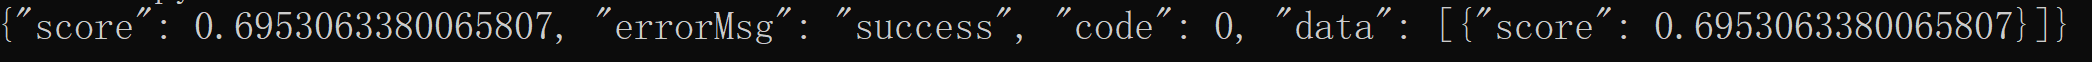


## 1.2 Word2Vec参数分析

以1.1中的参数为评价基准，分别计算不同**词向量维度**、**窗口大小**、**最小出现次数**的模型在WordSim353数据集上的词对相似度，计算其与人工标注之间的Spearman相关系数，用以评价词向量质量。

基准参数：
* vector_size=200 词向量维度

* window=10 窗口大小（考虑目标词前后各10个词）

* min_count=10 最小出现次数（忽略总频率低于10的词）


将参考代码调整后直接在jupyter中执行，不进行模型和预测得分的保存，直接输出不同参数设置下的Spearman相关系数。

In [1]:
'''
合并`word2vec.py`和`evaluation.py`
'''
import gensim
import multiprocessing
from gensim.models import word2vec
import numpy as np
from time import time
from scipy.stats import spearmanr
import matplotlib.pyplot as plt

# loading dataset
sents = word2vec.Text8Corpus('./Word2Vec/text8')

def main_function(vector_size, window, min_count):
    # training word2vec
    model = gensim.models.Word2Vec(sents,
                                   vector_size=vector_size,
                                   window=window,
                                   min_count=min_count,
                                   workers=multiprocessing.cpu_count())
    
    # testing on wordsim353
    sims = []
    ground_truth = []
    with open('Word2Vec/wordsim353/combined.csv') as f:
        for line in f.readlines()[1:]:
            l = line.strip().split(',')
            if l[0] in model.wv.key_to_index and l[1] in model.wv.key_to_index: # 过滤掉不在词表内的词
                sims.append(model.wv.similarity(l[0], l[1])) # 模型打分
                ground_truth.append(float(l[2]))
    
    # 计算Spearman相关系数
    spcor = spearmanr(ground_truth, sims)[0]

    return spcor

def plot_spcors(x, y, xlabel):
    plt.plot(x, y, 'ro--', linewidth=2, markersize=8) # red circles with dashed lines
    plt.xlabel(xlabel)
    plt.ylabel('Spearman Correlation')
    plt.grid(True)
    plt.show()


#### 1.2.1 词向量维度



In [2]:
vector_size_list = list(range(50, 550, 50))
window = 10
min_count = 10

spcors_1 = []
print('='*50)
print('计算不同词向量维度下的Spearman相关系数')
print('='*50)
for vector_size in vector_size_list:        
    spcor = main_function(vector_size, window, min_count)
    print('词向量维度：{}----Spearman相关系数:{}'.format(vector_size, spcor))
    spcors_1.append(spcor)

计算不同词向量维度下的Spearman相关系数
词向量维度：50----Spearman相关系数:0.6584435918095058
词向量维度：100----Spearman相关系数:0.6877531658690033
词向量维度：150----Spearman相关系数:0.6915918943473813
词向量维度：200----Spearman相关系数:0.6847565572208383
词向量维度：250----Spearman相关系数:0.692373511409419
词向量维度：300----Spearman相关系数:0.6885972532689131
词向量维度：350----Spearman相关系数:0.6896877787733422
词向量维度：400----Spearman相关系数:0.6990389816854752
词向量维度：450----Spearman相关系数:0.6864668671797465
词向量维度：500----Spearman相关系数:0.6949001988283412


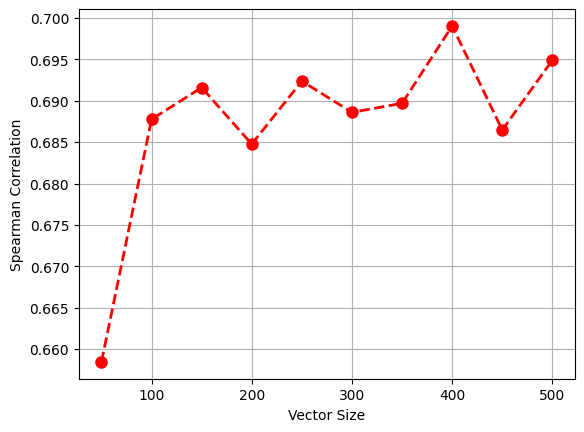

In [3]:
plot_spcors(vector_size_list, spcors_1, 'Vector Size')

直观推测词向量维度越大，模型越好。

实际比较500以内的词向量维度，发现$vector\_size=100$时，Spearman相关系数就到达0.69附近；继续增加词向量维度，评价系数基本稳定没有明显的变化。

**考虑到大维度的计算成本，本实验选择词向量维度在100~200之间比较合理。**


#### 1.2.2 窗口大小


In [4]:
vector_size = 200
window_list = list(range(2, 22, 2))
min_count = 10

spcors_2 = []
print('='*50)
print('计算不同窗口大小下的Spearman相关系数')
print('='*50)
for window in window_list:
    spcor = main_function(vector_size, window, min_count)
    print('窗口大小：{}----Spearman相关系数:{}'.format(window, spcor))
    spcors_2.append(spcor) 

计算不同窗口大小下的Spearman相关系数
窗口大小：2----Spearman相关系数:0.5852132711223741
窗口大小：4----Spearman相关系数:0.6254039974973764
窗口大小：6----Spearman相关系数:0.6614846347399893
窗口大小：8----Spearman相关系数:0.6776416612332138
窗口大小：10----Spearman相关系数:0.6781996312063867
窗口大小：12----Spearman相关系数:0.7018101396392197
窗口大小：14----Spearman相关系数:0.7183329701319002
窗口大小：16----Spearman相关系数:0.7151564928206232
窗口大小：18----Spearman相关系数:0.7133963377627303
窗口大小：20----Spearman相关系数:0.7141282736899249


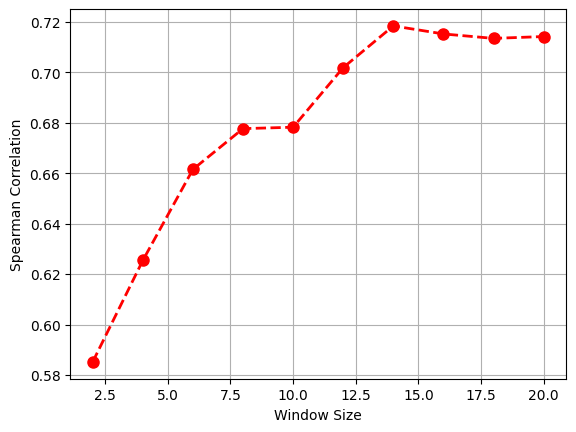

In [5]:
plot_spcors(window_list, spcors_2, 'Window Size')

同样直观推测窗口越大，考虑更长的上下文，训练出的模型越好。

实际比较20以内的词向量维度，发现$window=10$的训练结果明显优于$window=2$，继续增大窗口$window>14$以后模型相对稳定。

**本实验选择窗口大小在10~15之间比较合理。**

#### 1.2.3 最小出现次数

In [7]:
vector_size = 200
window = 10
min_count_list = list(range(2, 22, 2))

spcors_3 = []
print('='*50)
print('计算不同最小出现次数下的Spearman相关系数')
print('='*50)
for min_count in min_count_list:   
    spcor = main_function(vector_size, window, min_count)
    print('最小出现次数：{}----Spearman相关系数:{}'.format(min_count, spcor))
    spcors_3.append(spcor)

计算不同最小出现次数下的Spearman相关系数
最小出现次数：2----Spearman相关系数:0.6804505399650179
最小出现次数：4----Spearman相关系数:0.6764535769283313
最小出现次数：6----Spearman相关系数:0.6916340331317202
最小出现次数：8----Spearman相关系数:0.6881553699078491
最小出现次数：10----Spearman相关系数:0.6850990783122157
最小出现次数：12----Spearman相关系数:0.7004031633418951
最小出现次数：14----Spearman相关系数:0.6874823296645429
最小出现次数：16----Spearman相关系数:0.6979285675397578
最小出现次数：18----Spearman相关系数:0.6871848272950024
最小出现次数：20----Spearman相关系数:0.690575214075866


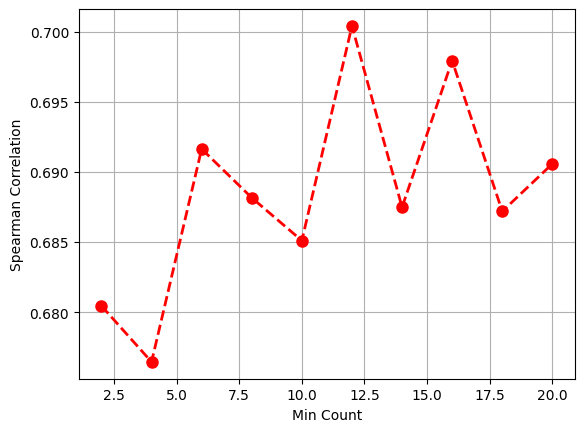

In [8]:
plot_spcors(min_count_list, spcors_3, 'Min Count')

**最小出现次数设定在20以内时，与评价模型效果没有明显的相关性。**

尝试继续增大最小出现次数：

计算不同最小出现次数下的Spearman相关系数
最小出现次数：20----Spearman相关系数:0.6937866275791026
最小出现次数：30----Spearman相关系数:0.7007592123443234
最小出现次数：40----Spearman相关系数:0.7040894620541125
最小出现次数：50----Spearman相关系数:0.6976213905806876
最小出现次数：60----Spearman相关系数:0.6892228018923339
最小出现次数：70----Spearman相关系数:0.7074600805064841
最小出现次数：80----Spearman相关系数:0.6935805326052351
最小出现次数：90----Spearman相关系数:0.6925674068433025
最小出现次数：100----Spearman相关系数:0.7031607055251875


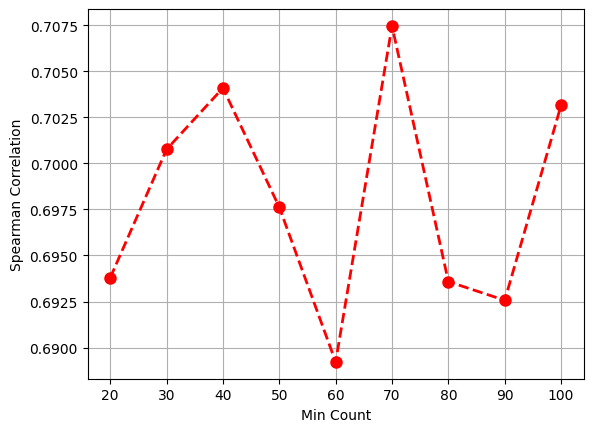

In [2]:
vector_size = 200
window = 10
min_count_list_ext = list(range(20, 101, 10))

spcors_3_ext = []
print('='*50)
print('计算不同最小出现次数下的Spearman相关系数')
print('='*50)
for min_count in min_count_list_ext:   
    spcor = main_function(vector_size, window, min_count)
    print('最小出现次数：{}----Spearman相关系数:{}'.format(min_count, spcor))
    spcors_3_ext.append(spcor)

plot_spcors(min_count_list_ext, spcors_3_ext, 'Min Count')

**最小出现次数增大到100时，Spearman相关系数在0.7附近波动，与评价模型效果没有明显的相关性。**

## 2.1 TransE代码补齐与执行

* 补全`TransE.py`中的函数`_calc()`和`loss()`
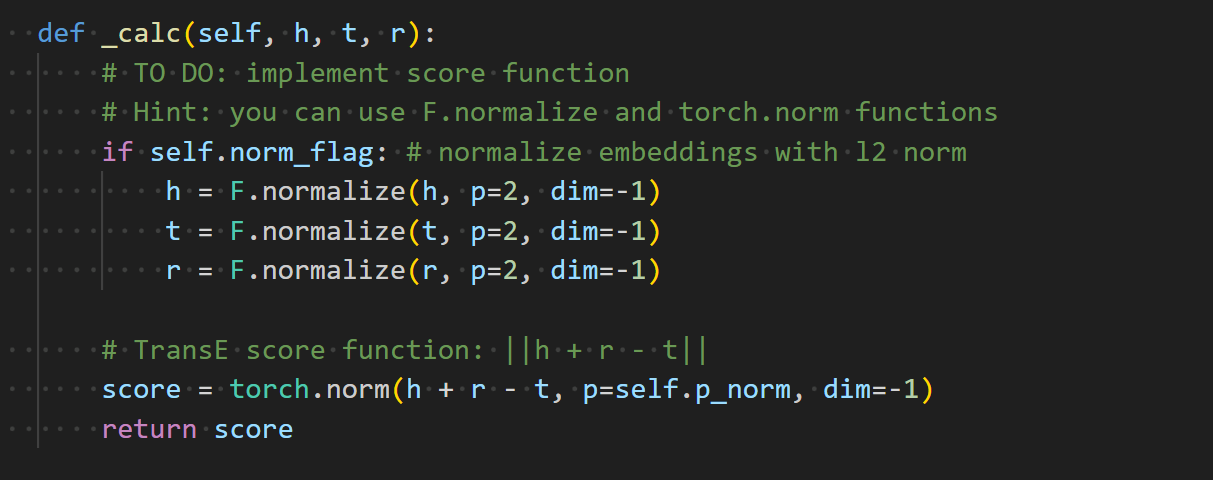
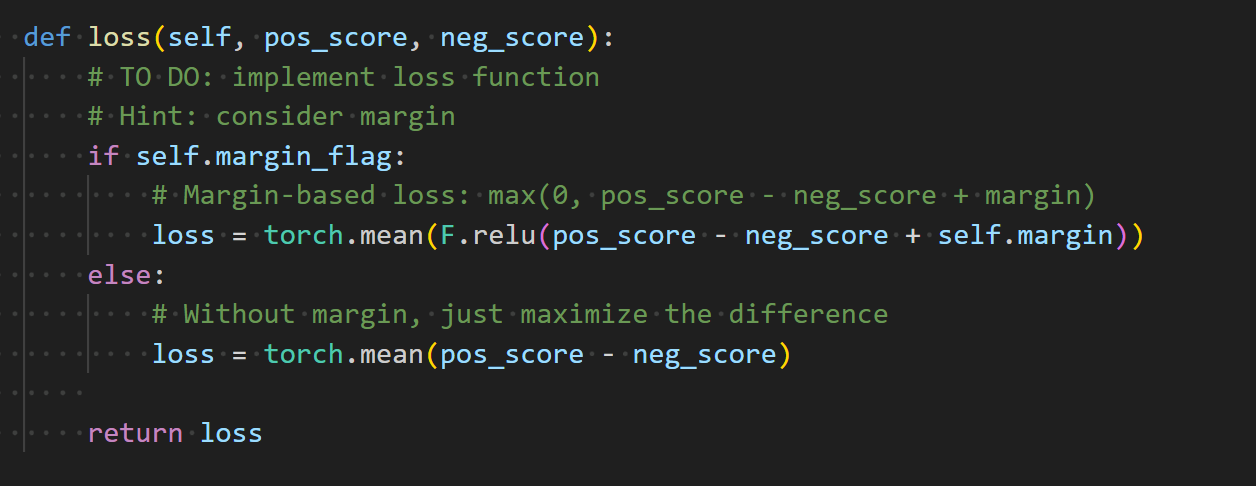

* 运行 `python TransE.py`，生成实体和关系的向量表示`entity2vec.txt`和`relation2vec.txt`

运行一个epoch的结果：
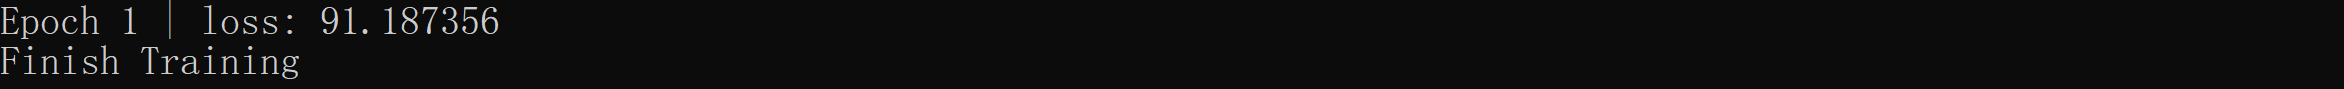

设置epochs值为500：
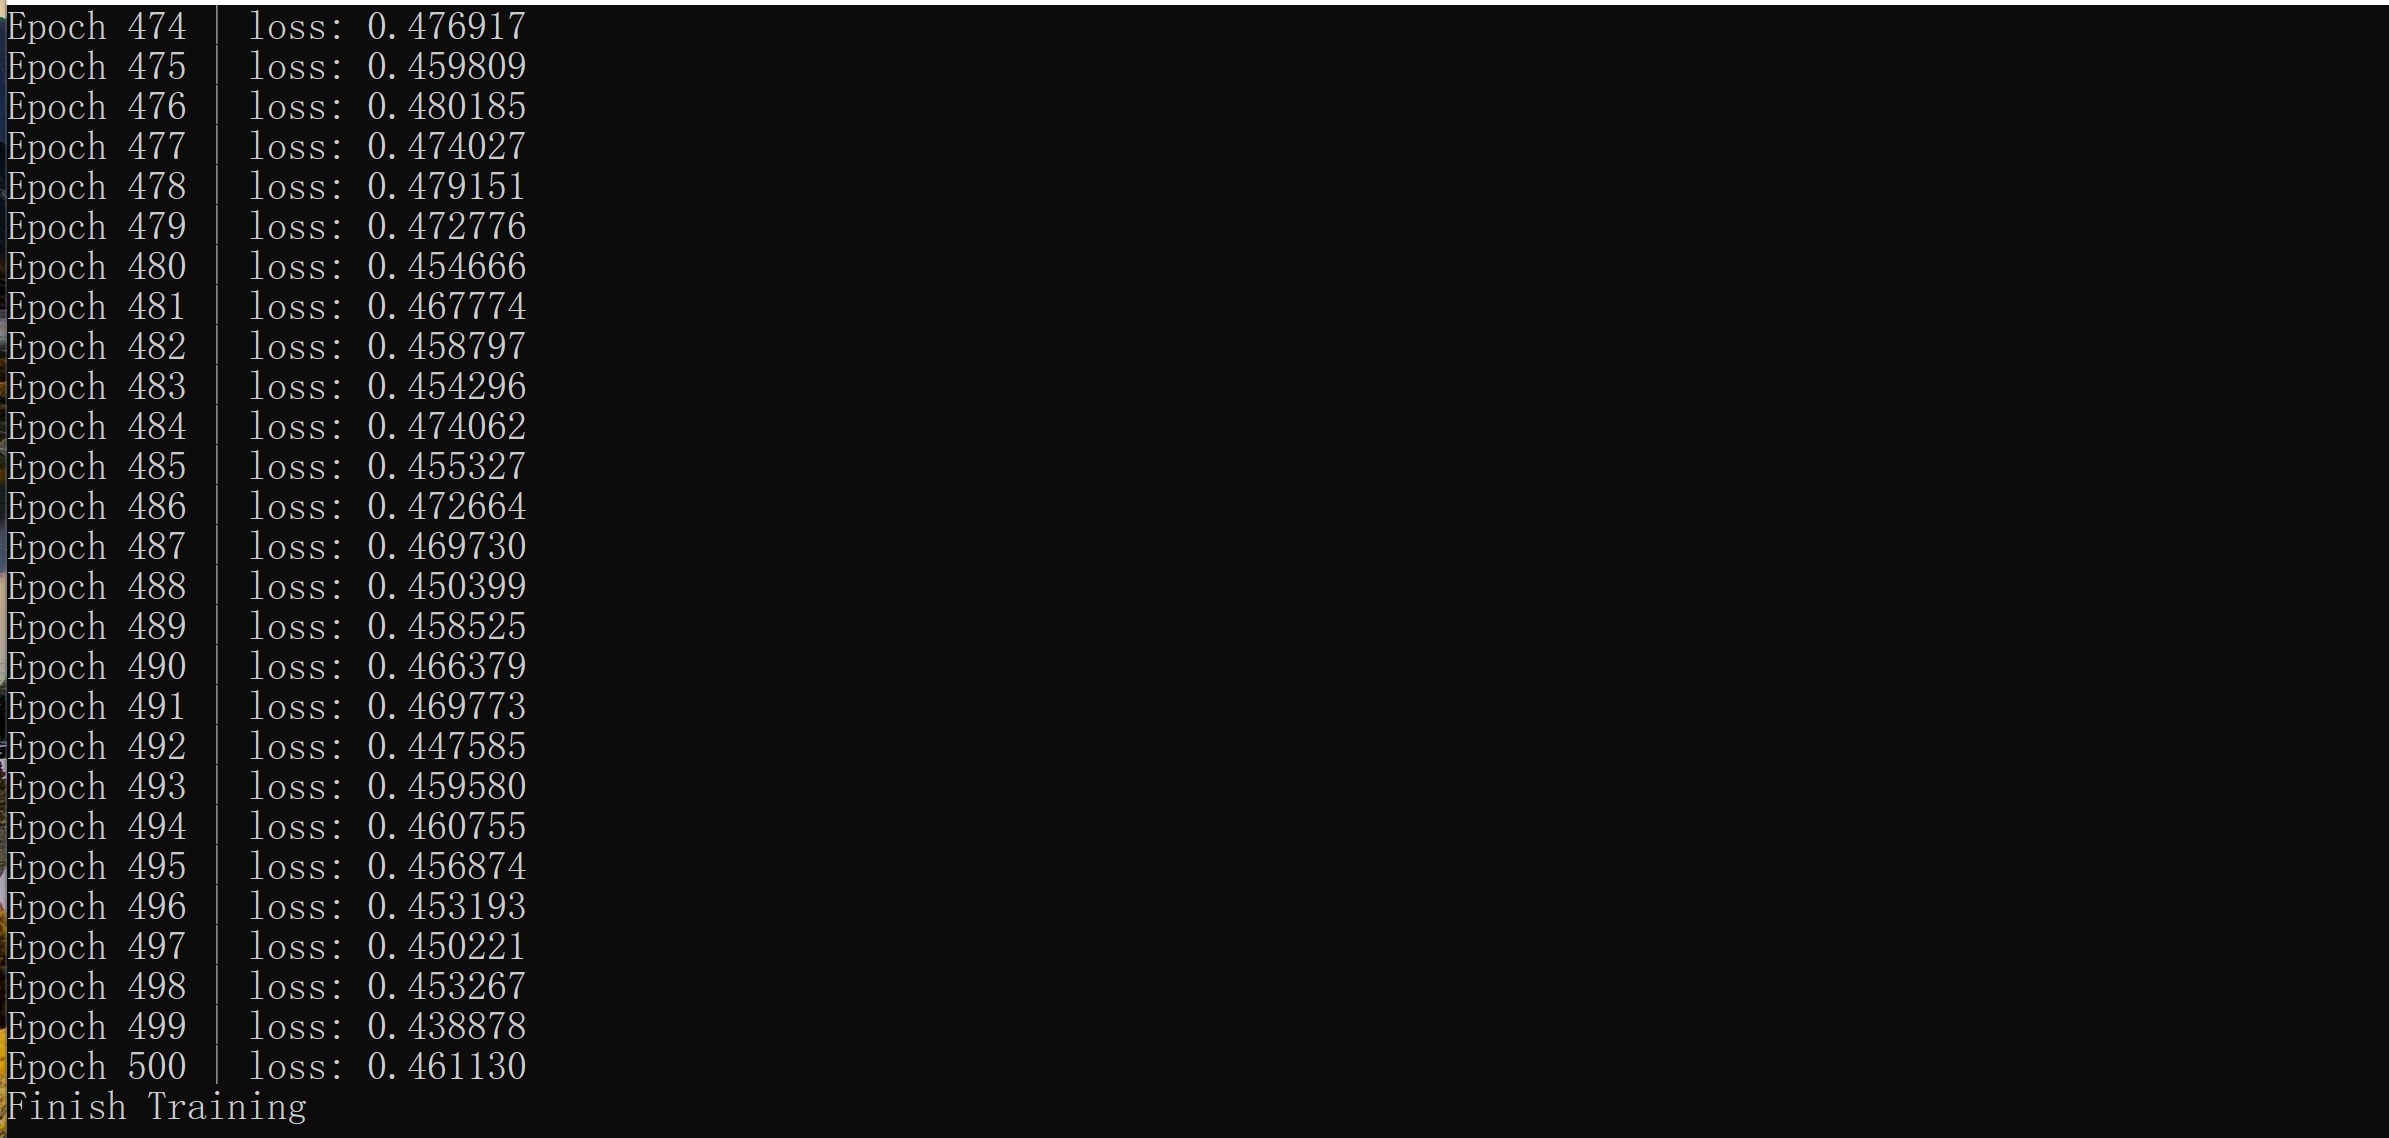

## 2.2 训练结果验证


In [4]:
import numpy as np

# 向量文件和ID映射文件路径
entity2vec_file = "./TransE/entity2vec.txt"
relation2vec_file = "./TransE/relation2vec.txt"
entity2id_file = "./TransE/data/entity2id.txt"
relation2id_file = "./TransE/data/relation2id.txt"

def load_id_mapping(filename):
    """加载ID映射文件"""
    mapping = {}
    with open(filename, 'r') as f:
        for line in f:
            parts = line.strip().split()
            if len(parts) >= 2:
                name, idx = parts[0], int(parts[1])
                mapping[name] = idx
    return mapping
    
def load_vectors(filename):
    """加载向量文件"""
    vectors = []
    with open(filename, 'r') as f:
        for line in f:
            vec = list(map(float, line.strip().split()))
            vectors.append(vec)
    return np.array(vectors)


# 加载ID映射
entity_to_id = load_id_mapping(entity2id_file)
relation_to_id = load_id_mapping(relation2id_file)
        
# 创建反向映射
id_to_entity = {v: k for k, v in entity_to_id.items()}
id_to_relation = {v: k for k, v in relation_to_id.items()}
        
# 加载向量
entity_embeddings = load_vectors(entity2vec_file)
relation_embeddings = load_vectors(relation2vec_file)
        
print(f"实体数量: {len(entity_embeddings)}, 关系数量: {len(relation_embeddings)}")
print(f"实体向量维度: {entity_embeddings.shape[1] if len(entity_embeddings) > 0 else 0}")

实体数量: 50000, 关系数量: 378
实体向量维度: 50


#### 2.2.1 给定头实体，关系，找出最接近的尾实体

In [5]:
"""
任务1: 给定头实体，关系，找出最接近的尾实体
"""
def task1_find_closest_tails(head_entity, relation, top_k=10):
    print(f"\n{'='*60}")
    print(f"任务1: 头实体={head_entity}, 关系={relation}")
    print(f"{'='*60}")
        
    # 获取ID 
    h_idx = entity_to_id[head_entity]
    r_idx = relation_to_id[relation]
        
    # 获取向量
    h = entity_embeddings[h_idx]
    r = relation_embeddings[r_idx]
        
    # 计算预测尾实体 h + r
    t_prime = h + r
        
    # 计算与所有尾实体的距离
    distances = []
    for i, t in enumerate(entity_embeddings):
        # TransE得分: ||h + r - t|| (L2范数)
        distance = np.linalg.norm(t_prime - t, ord=2)
        distances.append((i, distance))
        
    # 按距离排序（距离越小越接近）
    distances.sort(key=lambda x: x[1])
        
    # 输出top_k结果
    print(f"\nTop {top_k} 最接近的尾实体:")
    print(f"{'排名':<6} {'实体ID':<15} {'实体名称':<20} {'距离':<12}")
    print("-" * 55)
        
    for i in range(min(top_k, len(distances))):
        entity_id, dist = distances[i]
        entity_name = id_to_entity.get(entity_id, f"未知实体_{entity_id}")
        print(f"{i+1:<6} {entity_id:<15} {entity_name:<20} {dist:.6f}")
        
    return distances[:top_k]

# 给定头实体Q30，关系P36，找最接近的尾实体
top_tails = task1_find_closest_tails('Q30', 'P36', top_k=10)


任务1: 头实体=Q30, 关系=P36

Top 10 最接近的尾实体:
排名     实体ID            实体名称                 距离          
-------------------------------------------------------
1      49369           Q6782246             0.453197
2      20626           Q192410              0.453603
3      4155            Q485716              0.454295
4      26636           Q2967                0.454770
5      26294           Q101859              0.454779
6      25769           Q1366796             0.455100
7      39095           Q3069                0.455294
8      11705           Q135744              0.455317
9      7462            Q842858              0.455444
10     118             Q30                  0.455553


* 头实体 Q30: United States
* 关系 P36: capital
* 期望尾实体 Q61: Washington, D.C.

最终模型训练了500轮，损失函数值从91下降到了0.46。

查询Top5尾实体的实际含义，发现模型预测结果与期望相差甚远，在Top10甚至出现了头实体Q30：
| 排名 | 关系ID | 关系名称 | 距离 | 真实含义 |
| :--- | :--- | :--- | :--- | :--- |
| 1 | 49369 | Q6782246 | 0.453197 | Masaaki |
| 2 | 20626 | Q192410 | 0.453603 | Jennifer Hudson |
| 3 | 4155 | Q485716 | 0.454295 | Glendale |
| 4 | 26636 | Q2967 | 0.454770 | Rendsburg-Eckernförde |
| 5 | 26294 | Q101859 | 0.454779 | VfL Wolfsburg |

In [6]:
'''
考虑到过学习的可能性，尝试使用训练200轮的模型进行预测任务
'''
# 向量文件路径
entity2vec_file = "./TransE/entity2vec_epochs200.txt"
relation2vec_file = "./TransE/relation2vec_epochs200.txt"

# 加载向量
entity_embeddings = load_vectors(entity2vec_file)
relation_embeddings = load_vectors(relation2vec_file)

# 给定头实体Q30，关系P36，找最接近的尾实体
top_tails = task1_find_closest_tails('Q30', 'P36', top_k=10)


任务1: 头实体=Q30, 关系=P36

Top 10 最接近的尾实体:
排名     实体ID            实体名称                 距离          
-------------------------------------------------------
1      8144            Q172                 0.423863
2      46570           Q4671098             0.424092
3      41244           Q507285              0.424347
4      42359           Q494504              0.424466
5      4489            Q172980              0.424478
6      49904           Q109005              0.424646
7      48946           Q170263              0.424716
8      36973           Q2273497             0.425379
9      32063           Q207223              0.425958
10     18754           Q9652                0.426643


使用训练了200轮的模型，发现似乎预测结果似乎有改善（Top1是城市名），但结果仍然很不理想：

| 排名 | 关系ID | 关系名称 | 距离 | 真实含义 |
| :--- | :--- | :--- | :--- | :--- |
| 1 | 8144 | Q172 | 0.423863 | Toronto |
| 2 | 46570 | Q4671098 | 0.424092 | Academia Venezolana de la Lengua |
| 3 | 41244 | Q507285 | 0.424347 | Lumière and Company |
| 4 | 42359 | Q494504 | 0.424466 | Bludenz |
| 5 | 4489 | Q172980 | 0.424478 | Western film |

#### 2.2.2 给定头实体，尾实体，找出最接近的关系

In [11]:
"""
任务2: 给定头实体，尾实体，找出最接近的关系
"""
def task2_find_closest_relations(head_entity, tail_entity, top_k=10):   
    print(f"\n{'='*60}")
    print(f"任务2: 头实体={head_entity}, 尾实体={tail_entity}")
    print(f"{'='*60}")
        
    # 获取ID        
    h_idx = entity_to_id[head_entity]
    t_idx = entity_to_id[tail_entity]
        
    # 获取向量
    h = entity_embeddings[h_idx]
    t = entity_embeddings[t_idx]
        
    # 计算预测关系 t - h
    r_prime = t - h
        
    # 计算与所有关系的距离
    distances = []
    for i, r in enumerate(relation_embeddings):
        # TransE得分: ||h + r - t|| 等价于 ||r - (t - h)||
        distance = np.linalg.norm(r - r_prime , ord=2)
        distances.append((i, distance))
        
    # 按距离排序
    distances.sort(key=lambda x: x[1])
        
    # 输出top_k结果
    print(f"\nTop {top_k} 最接近的关系:")
    print(f"{'排名':<6} {'关系ID':<15} {'关系名称':<20} {'距离':<12}")
    print("-" * 55)
        
    for i in range(min(top_k, len(distances))):
        rel_id, dist = distances[i]
        rel_name = id_to_relation.get(rel_id, f"未知关系_{rel_id}")
        print(f"{i+1:<6} {rel_id:<15} {rel_name:<20} {dist:.6f}")
        
    return distances[:top_k]

# 给定头实体Q30，尾实体Q49，找最接近的关系
top_relations = task2_find_closest_relations('Q30', 'Q49', top_k=10)
    


任务2: 头实体=Q30, 尾实体=Q49

Top 10 最接近的关系:
排名     关系ID            关系名称                 距离          
-------------------------------------------------------
1      22              P35                  0.404447
2      320             P1290                0.418547
3      14              P150                 0.419045
4      133             P488                 0.419603
5      28              P1589                0.421681
6      328             P814                 0.422458
7      305             P397                 0.427488
8      266             P1533                0.430228
9      351             P248                 0.431188
10     340             P1891                0.432199


* 头实体 Q30: United States
* 尾实体 Q49: North America
* 期望关系 P30: continent

该预测关系的任务结果也不理想：
| 排名 | 关系ID | 关系名称 | 距离 | 真实含义 |
| :--- | :--- | :--- | :--- | :--- |
| 1 | 22 | P35 | 0.404447 | head of state |
| 2 | 320 | P1290 | 0.418547 | godparent |
| 3 | 14 | P150 | 0.419045 | contains the administrative territorial entity |
| 4 | 133 | P488 | 0.419603 | chairperson |
| 5 | 28 | P1589 | 0.421681 | lowest point |

#### 2.2.3 原因分析

嵌入向量统计:
  实体向量: 形状 (50000, 50)
  关系向量: 形状 (378, 50)

实体向量统计:
  均值: 0.000009
  标准差: 0.006497
  范围: [-0.046970, 0.044318]
  零向量数量: 0/50000
  范数统计: 均值=0.0458, 标准差=0.0035
  范数范围: [0.0336, 0.1332]


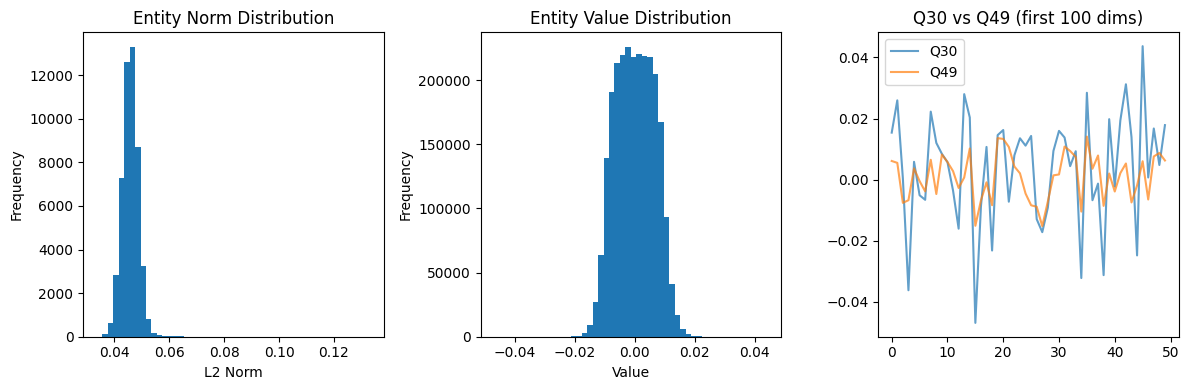

(array([[-0.004254, -0.014152,  0.002502, ...,  0.010714, -0.011305,
         -0.013843],
        [ 0.000469, -0.009196,  0.001815, ..., -0.003306, -0.011387,
          0.005407],
        [ 0.010185,  0.003342, -0.013631, ...,  0.016908,  0.010019,
          0.019261],
        ...,
        [-0.00457 ,  0.003064, -0.008639, ..., -0.007417,  0.004954,
         -0.007613],
        [ 0.00838 ,  0.001181, -0.0043  , ..., -0.006781, -0.002181,
         -0.007063],
        [-0.000695,  0.000643,  0.005442, ..., -0.007797,  0.006824,
          0.006215]]),
 array([[-0.112569, -0.005223, -0.075128, ...,  0.066007, -0.096721,
         -0.093102],
        [-0.055109, -0.103145,  0.072146, ...,  0.039525, -0.113129,
          0.01948 ],
        [-0.017535, -0.056455,  0.009775, ...,  0.094305, -0.093436,
          0.039144],
        ...,
        [-0.095952, -0.012525,  0.006014, ...,  0.105644, -0.096877,
          0.11788 ],
        [-0.076046,  0.049493,  0.111153, ..., -0.046755,  0.047031,
   

In [12]:
def analyze_embeddings_quality():
    """分析嵌入向量的质量"""
    
    # 加载向量
    ent_emb = np.loadtxt('./TransE/entity2vec.txt')
    rel_emb = np.loadtxt('./TransE/relation2vec.txt')
    
    print("嵌入向量统计:")
    print(f"  实体向量: 形状 {ent_emb.shape}")
    print(f"  关系向量: 形状 {rel_emb.shape}")
    
    # 计算统计信息
    ent_mean = np.mean(ent_emb)
    ent_std = np.std(ent_emb)
    ent_min = np.min(ent_emb)
    ent_max = np.max(ent_emb)
    
    print(f"\n实体向量统计:")
    print(f"  均值: {ent_mean:.6f}")
    print(f"  标准差: {ent_std:.6f}")
    print(f"  范围: [{ent_min:.6f}, {ent_max:.6f}]")
    
    # 检查是否有退化的向量
    zero_entities = np.sum(np.linalg.norm(ent_emb, axis=1) < 1e-6)
    print(f"  零向量数量: {zero_entities}/{len(ent_emb)}")
    
    # 检查向量范数分布
    norms = np.linalg.norm(ent_emb, axis=1)
    print(f"  范数统计: 均值={np.mean(norms):.4f}, 标准差={np.std(norms):.4f}")
    print(f"  范数范围: [{np.min(norms):.4f}, {np.max(norms):.4f}]")
    
    # 可视化范数分布
    import matplotlib.pyplot as plt
    plt.figure(figsize=(12, 4))
    
    plt.subplot(1, 3, 1)
    plt.hist(norms, bins=50)
    plt.title('Entity Norm Distribution')
    plt.xlabel('L2 Norm')
    plt.ylabel('Frequency')
    
    plt.subplot(1, 3, 2)
    plt.hist(ent_emb.flatten(), bins=50)
    plt.title('Entity Value Distribution')
    plt.xlabel('Value')
    plt.ylabel('Frequency')
    
    plt.subplot(1, 3, 3)
    # 检查Q30和Q49的向量
    if 'Q30' in entity_to_id and 'Q49' in entity_to_id:
        q30_idx = entity_to_id['Q30']
        q49_idx = entity_to_id['Q49']
        
        q30_vec = ent_emb[q30_idx]
        q49_vec = ent_emb[q49_idx]
        
        plt.plot(q30_vec[:100], label='Q30', alpha=0.7)
        plt.plot(q49_vec[:100], label='Q49', alpha=0.7)
        plt.title('Q30 vs Q49 (first 100 dims)')
        plt.legend()
    
    plt.tight_layout()
    plt.savefig('embedding_analysis.png')
    plt.show()
    
    return ent_emb, rel_emb

analyze_embeddings_quality()

**上述结果显示向量范数太小，模型可能没有归一化，由于时间问题，尝试在推理时手动归一化，结果有了一些改善。**

In [15]:
def task1_with_normalization(head='Q30', rel='P36', top_k=10):
    """在推理时手动归一化向量"""
    
    # 获取向量
    h_idx = entity_to_id[head]
    r_idx = relation_to_id[rel]
    
    h = ent_emb[h_idx]
    r = rel_emb[r_idx]
    
    # 手动L2归一化
    h_norm = h / np.linalg.norm(h)
    r_norm = r / np.linalg.norm(r)
    
    # 预测向量
    t_pred = h_norm + r_norm
    
    # 归一化所有实体向量
    ent_emb_norm = ent_emb / np.linalg.norm(ent_emb, axis=1, keepdims=True)
    
    # 计算距离
    distances = []
    for i, t in enumerate(ent_emb_norm):
        dist = np.linalg.norm(t_pred - t)
        distances.append((i, dist))
    
    distances.sort(key=lambda x: x[1])
    
    print(f"\nTop {top_k} 预测 (使用归一化):")
    for rank, (idx, dist) in enumerate(distances[:top_k], 1):
        name = id_to_entity.get(idx, f"未知{idx}")
        print(f"{rank:2d}. {name:15s} (ID: {idx:5d}) | 距离: {dist:.6f}")
    
    # 检查Q61的排名
    if 'Q61' in entity_to_id:
        q61_idx = entity_to_id['Q61']
        for rank, (idx, _) in enumerate(distances, 1):
            if idx == q61_idx:
                print(f"\n✅ Q61 的排名: {rank}")
                break

# 使用
task1_with_normalization()


Top 10 预测 (使用归一化):
 1. Q30             (ID:   118) | 距离: 1.000000
 2. Q16             (ID:   216) | 距离: 1.142721
 3. Q1384           (ID:  1335) | 距离: 1.173571
 4. Q668            (ID:     8) | 距离: 1.197544
 5. Q1649           (ID: 20528) | 距离: 1.224816
 6. Q174193         (ID:  3424) | 距离: 1.225006
 7. Q917            (ID:  8138) | 距离: 1.243289
 8. Q1391           (ID:  2192) | 距离: 1.252770
 9. Q724            (ID:  1840) | 距离: 1.252861
10. Q6782246        (ID: 49369) | 距离: 1.266303

✅ Q61 的排名: 85
